In [3]:
import numpy as np
import pandas as pd

In [4]:
df = pd.read_csv('../data/student-mat.csv', sep=';') 
#pd.read_csv() tells Pandas: Read this CSV file and convert it into a DataFrame.

In [5]:
df.head()
#head() shows the first 5 rows by default.

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [6]:
df.shape
#Find out how many rows and columns are in the DataFrame using shape. The output is a tuple of the form (rows, columns).

(395, 33)

In [7]:
df.columns
#Look at the column names

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')

In [8]:
df.info()
#Check the data types

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [9]:
df.isnull().sum()
#check the missing values in the dataset. The output is a series with the column names as the index and the number of missing values as the values.

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [10]:
df["pass"] = (df["G3"] >= 10).astype(int)
#Store the pass/fail information in a new column called "pass". The expression (df["G3"] >= 10) creates a boolean series where each value is True if the corresponding G3 value is greater than or equal to 10, and False otherwise. The astype(int) method converts the boolean values to integers (1 for True and 0 for False).

In [11]:
df["pass"].value_counts()
#Check how many students pass and fail

pass
1    265
0    130
Name: count, dtype: int64

In [12]:
df["pass"].value_counts(normalize=True) * 100
#This gives us the percentage of students in each class.

pass
1    67.088608
0    32.911392
Name: proportion, dtype: float64

In [13]:
features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "Medu",
    "Fedu"
]
x = df[features]
#Create our feature matrix

In [14]:
y = df["pass"]
#create our target vector

In [15]:
x.head()
#check the first 5 rows of the feature matrix

,age,studytime,failures,absences,Medu,Fedu
0,18,2,0,6,4,4
1,17,2,0,4,1,1
2,15,2,3,10,1,1
3,15,3,0,2,4,2
4,16,2,0,4,3,3


In [16]:
y.head()
#check the first 5 rows of the target vector

0    0
1    0
2    1
3    1
4    1
Name: pass, dtype: int64

In [17]:
import matplotlib.pyplot as plt #malplotlib is a library for creating visualizations in Python. It is often used in conjunction with Pandas and NumPy to create plots and charts from data stored in DataFrames and arrays.
import seaborn as sns #Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics.

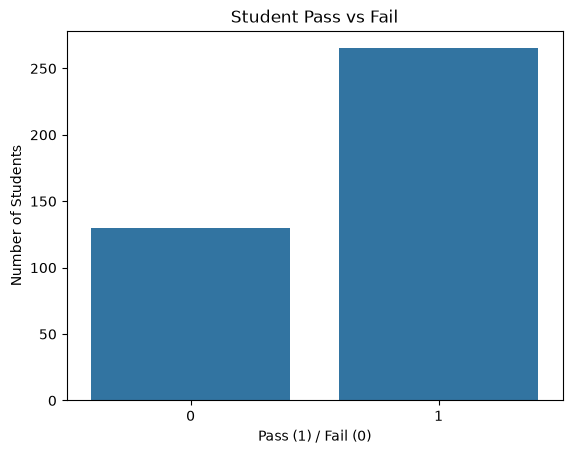

In [18]:
sns.countplot(x="pass", data=df) #this function creates a bar plot showing the counts of observations in each categorical bin using bars. The x parameter specifies the column to be plotted, and the data parameter specifies the DataFrame containing the data.

plt.title("Student Pass vs Fail") #add a title to the plot
plt.xlabel("Pass (1) / Fail (0)") #add a label to the x-axis
plt.ylabel("Number of Students") #add a label to the y-axis
plt.show() #display the plot

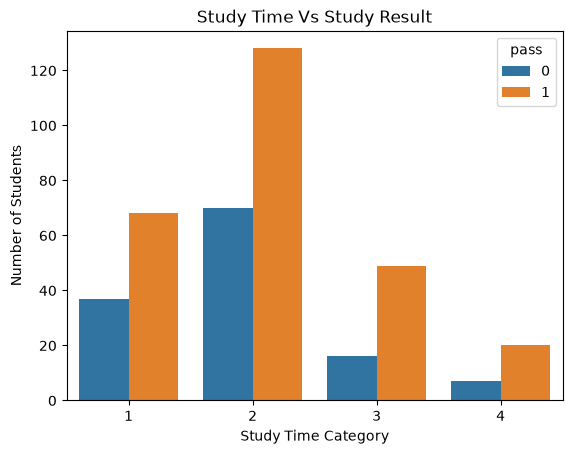

In [19]:
sns.countplot(x="studytime", hue="pass", data=df) #this function creates a bar plot showing the counts of observations in each categorical bin using bars. The x parameter specifies the column to be plotted, and the data parameter specifies the DataFrame containing the data. The hue parameter adds a second categorical variable to the plot, which is used to color the bars.

plt.title("Study Time Vs Study Result") #add a title to the plot
plt.xlabel("Study Time Category") #add a label to the x-axis
plt.ylabel("Number of Students") #add a label to the y-axis

plt.show() #display the plot

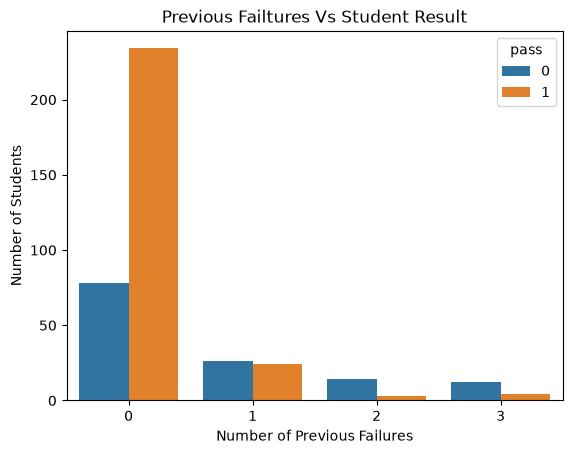

In [20]:
sns.countplot(x="failures", hue="pass", data=df) #this function creates a bar plot showing the counts of observations in each categorical bin using bars. The x parameter specifies the column to be plotted, and the data parameter specifies the DataFrame containing the data. The hue parameter adds a second categorical variable to the plot, which is used to color the bars.

plt.title("Previous Failtures Vs Student Result") #add a title to the plot
plt.xlabel("Number of Previous Failures") #add a label to the x-axis
plt.ylabel("Number of Students") #add a label to the y-axis

plt.show() #display the plot

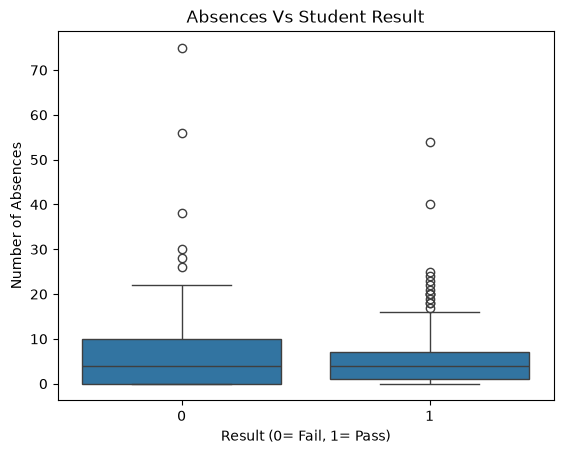

In [21]:
sns.boxplot(x="pass", y="absences", data=df) #this function creates a box plot showing the distribution of a continuous variable (absences) across different categories of a categorical variable (pass). The x parameter specifies the categorical variable, the y parameter specifies the continuous variable, and the data parameter specifies the DataFrame containing the data.

plt.title("Absences Vs Student Result") #add a title to the plot
plt.xlabel("Result (0= Fail, 1= Pass)") #add a label to the x-axis
plt.ylabel("Number of Absences") #add a label to the y-axis

plt.show() #display the plot

In [22]:
from sklearn.model_selection import train_test_split 
#The train_test_split function from the sklearn.model_selection module is used to split a dataset into training and testing sets. It takes in the feature matrix (X) and target vector (y) as inputs, along with parameters such as test_size (the proportion of the dataset to include in the test split) and random_state (a seed value for reproducibility). The function returns four outputs: X_train, X_test, y_train, and y_test, which represent the training and testing sets for both features and target variables.


In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42, stratify=y)
#X_train is the feature matrix for the training set
# X_test is the feature matrix for the testing set
# y_train is the target vector for the training set 
#y_test is the target vector for the testing set. 
#The test_size parameter specifies that 20% of the data should be used for testing 
#the random_state parameter ensures that the split is reproducible.
#stratify=y ensures that the proportion of classes in the target variable is maintained in both the training and testing sets.

In [25]:
print ("Training data: ", X_train.shape) # Print the shape of the training data
print ("Testing data: ", X_test.shape) # Print the shape of the testing data

Training data:  (316, 6)
Testing data:  (79, 6)


In [26]:
print(y_train.value_counts(normalize=True) * 100) #Print the percentage of each class in the training data
print(y_test.value_counts(normalize=True) * 100) #Print the percentage of each class in the testing data

pass
1    67.088608
0    32.911392
Name: proportion, dtype: float64
pass
1    67.088608
0    32.911392
Name: proportion, dtype: float64


In [27]:
from sklearn.compose import ColumnTransformer #ColumnTransformer is a class in the sklearn.compose module that allows you to apply different preprocessing steps to different columns of a dataset. It takes a list of tuples as input, where each tuple specifies the name of the transformer, the transformer object, and the list of columns to which the transformer should be applied. The ColumnTransformer can be used to apply transformations such as scaling, encoding, or imputation to specific columns while leaving other columns unchanged.
from sklearn.preprocessing import OneHotEncoder #OneHotEncoder is a class in the sklearn.preprocessing module that is used to convert categorical variables into a format that can be provided to machine learning algorithms to improve predictions. It creates binary columns for each category in the original categorical column, where each column represents the presence (1) or absence (0) of a specific category.

ImportError: DLL load failed while importing _loss: An Application Control policy has blocked this file.

In [42]:
numeric_features = [
    "age",
    "absences"
] #This is a list of numeric features that will be used in the machine learning model. These features are continuous variables that can take on any value within a range.

categorical_features =[
    "studytime",
    "failures",
    "Medu",
    "Fedu"
] #This is a list of categorical features that will be used in the machine learning model. These features are discrete variables that can take on a limited number of values, such as categories or labels. The OneHotEncoder will be applied to these features to convert them into a format suitable for machine learning algorithms.

In [43]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features), #This line specifies that the numeric features should be passed through without any transformation. The "num" is the name of the transformer, "passthrough" indicates that no transformation should be applied, and numeric_features is the list of numeric features to be passed through.
        ("cat", OneHotEncoder(handle_unknown='ignore'), categorical_features) #This line specifies that the categorical features should be transformed using OneHotEncoder. The "cat" is the name of the transformer, OneHotEncoder() is the transformer object that will be applied to the categorical features, and categorical_features is the list of categorical features to be transformed.
    ]
)

In [28]:
from sklearn.linear_model import LogisticRegression
#LogisticRegression is a class in the sklearn.linear_model module that implements logistic regression, a statistical method for binary classification. It models the relationship between a set of independent variables (features) and a binary dependent variable (target) by estimating the probabilities of the target variable belonging to one of the two classes. The LogisticRegression class provides methods for fitting the model to training data, making predictions on new data, and evaluating the model's performance.

model = LogisticRegression(max_iter=1000) 
#This line creates an instance of the LogisticRegression class and assigns it to the variable model. The max_iter parameter specifies the maximum number of iterations for the optimization algorithm used to fit the model. In this case, it is set to 1000, which means that the algorithm will run for a maximum of 1000 iterations before stopping. This is useful for ensuring that the model converges to a solution, especially when dealing with complex datasets or when the default number of iterations is insufficient.

In [44]:
from sklearn.pipeline import Pipeline 
#Pipeline is a class in the sklearn.pipeline module that allows you to create a linear sequence of data processing steps, including preprocessing and modeling. It takes a list of tuples as input, where each tuple specifies the name of the step and the corresponding transformer or estimator object. The Pipeline class provides methods for fitting the entire sequence of steps to training data, making predictions on new data, and evaluating the performance of the model.

pipeline = Pipeline([
    ("preprocessing", preprocessor), #This line adds the preprocessor step to the pipeline. The name of the step is "preprocessing", and the preprocessor object created earlier is used to transform the input data.
    ("model", model) #This line adds the model step to the pipeline. The name of the step is "model", and the model object created earlier (LogisticRegression) is used to fit the transformed data and make predictions.
])

In [45]:
pipeline.fit(X_train, y_train) 
#this line fits the entire pipeline to the training data. It first applies the preprocessing steps defined in the preprocessor (e.g., passing through numeric features and one-hot encoding categorical features) to the training feature matrix (X_train). Then, it fits the logistic regression model to the transformed training data and the corresponding target vector (y_train). This allows the model to learn the relationships between the features and the target variable based on the training data.

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','studytime','failures','absences','Medu','Fedu']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns

In [46]:
y_pred =pipeline.predict(X_test)
#This line makes predictions on the test data using the fitted pipeline. It first applies the same preprocessing steps to the test feature matrix (X_test) as were applied to the training data, and then uses the fitted logistic regression model to predict the target values for the test data.

In [47]:
from sklearn.metrics import accuracy_score 
#accuracy_score is a function in the sklearn.metrics module that calculates the accuracy of a classification model. It takes two inputs: the true labels (y_true) and the predicted labels (y_pred) and returns the proportion of correctly classified instances as a float value between 0 and 1. The accuracy score is a common evaluation metric for classification models, indicating how well the model performs in predicting the target variable.

accuracy = accuracy_score(y_test, y_pred)
#this line calculates the accuracy of the model's predictions on the test data by comparing the true labels (y_test) with the predicted labels (y_pred). The resulting accuracy score is stored in the variable accuracy, which can be used to evaluate the performance of the model.

print("Accuracy: ", accuracy) 
#this line prints the accuracy score of the model's predictions on the test data. The accuracy score is a measure of how well the model performs in predicting the target variable, with higher values indicating better performance.

Accuracy:  0.6962025316455697


In [48]:
from sklearn.metrics import confusion_matrix 
#this line imports the confusion_matrix function from the sklearn.metrics module. The confusion matrix is a performance measurement tool for classification models, which shows the number of true positive, true negative, false positive, and false negative predictions made by the model. It provides a more detailed view of the model's performance compared to accuracy alone.

cm = confusion_matrix(y_test, y_pred)
#this line calculates the confusion matrix for the model's predictions on the test data by comparing the true labels (y_test) with the predicted labels (y_pred). The resulting confusion matrix is stored in the variable cm, which can be used to evaluate the performance of the model in terms of true positives, true negatives, false positives, and false negatives.

print (cm) 

[[ 9 17]
 [ 7 46]]


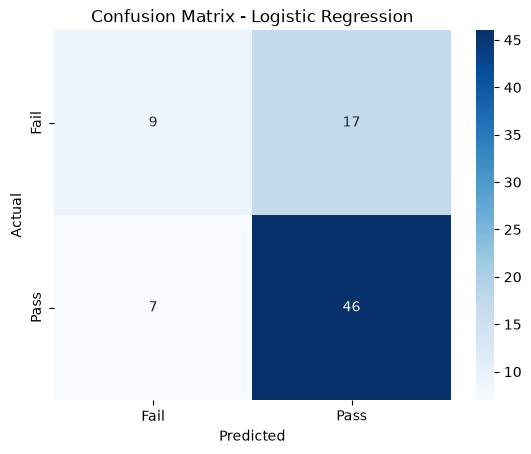

In [49]:
sns.heatmap( 
    cm,
    annot=True, #annot=True adds numerical annotations to each cell in the heatmap, displaying the values of the confusion matrix.
    fmt="d", #Format the numbers as integers
    cmap="Blues", #This tells Seaborn to use a blue color gradient.
    xticklabels=["Fail", "Pass"], #The X-axis represents what the model predicted.
    yticklabels=["Fail", "Pass"] #The Y-axis represents what actually happened.
)
#this line creates a heatmap visualization of the confusion matrix using the seaborn library. The cm variable contains the confusion matrix data, and the annot=True parameter adds numerical annotations to each cell in the heatmap. The fmt="d" parameter specifies that the annotations should be formatted as integers. The cmap="Blues" parameter sets the color map to a blue gradient. The xticklabels and yticklabels parameters specify the labels for the x-axis and y-axis ticks, respectively, indicating the classes "Fail" and "Pass".

plt.xlabel("Predicted") #The horizontal direction represents the model's prediction.
plt.ylabel("Actual") #The vertical direction represents what actually happened.
plt.title("Confusion Matrix - Logistic Regression") #Just gives the visualization a clear title.

plt.show()


In [50]:
from sklearn.metrics import classification_report
#this line imports the classification_report function from the sklearn.metrics module. The classification report is a performance evaluation tool for classification models that provides a summary of precision, recall, F1-score, and support for each class. It helps to assess the model's performance in terms of its ability to correctly classify instances of each class.

print (classification_report(
    y_test, 
    y_pred, 
    target_names=["Fail", "Pass"]
))
#This line prints the classification report, which includes precision, recall, F1-score, and support for each class.



              precision    recall  f1-score   support

        Fail       0.56      0.35      0.43        26
        Pass       0.73      0.87      0.79        53

    accuracy                           0.70        79
   macro avg       0.65      0.61      0.61        79
weighted avg       0.67      0.70      0.67        79



In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "age",
    "absences"
]

categorical_features = [
    "studytime",
    "failures",
    "Medu",
    "Fedu"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [53]:
from sklearn.naive_bayes import GaussianNB
#this line imports the GaussianNB class from the sklearn.naive_bayes module. GaussianNB is a machine learning algorithm based on the Naive Bayes classifier, which assumes that the features follow a Gaussian (normal) distribution. It is used for classification tasks and is particularly effective for high-dimensional datasets. The GaussianNB class provides methods for fitting the model to training data, making predictions on new data, and evaluating the model's performance.

nb_model = GaussianNB()
#this line creates an instance of the GaussianNB class and assigns it to the variable nb_model. This instance can be used to fit the model to training data, make predictions on new data, and evaluate the model's performance in classification tasks.

X_train_transformed = preprocessor.fit_transform(X_train) #this line applies the preprocessing steps defined in the preprocessor to the training feature matrix (X_train) and transforms it into a new feature matrix (X_train_transformed). The fit_transform method first fits the preprocessor to the training data, learning any necessary parameters (e.g., calculating means and standard deviations for scaling, or determining unique categories for one-hot encoding), and then applies the transformations to the training data. The resulting X_train_transformed is a transformed version of the original training feature matrix, ready for use in model training.
X_test_transformed = preprocessor.transform(X_test) #this line applies the same preprocessing steps defined in the preprocessor to the test feature matrix (X_test) and transforms it into a new feature matrix (X_test_transformed). The transform method uses the parameters learned during the fit_transform step on the training data to ensure that the test data is transformed consistently. The resulting X_test_transformed is a transformed version of the original test feature matrix, ready for use in model evaluation and prediction.

nb_model.fit(X_train_transformed, y_train)
#this line fits the Gaussian Naive Bayes model (nb_model) to the transformed training data (X_train_transformed) and the corresponding target vector (y_train). The fit method estimates the parameters of the Gaussian distribution for each feature based on the training data, allowing the model to learn the relationships between the features and the target variable. Once fitted, the model can be used to make predictions on new data.

nb_pred = nb_model.predict(X_test_transformed)
#this line makes predictions on the transformed test data (X_test_transformed) using the fitted Gaussian Naive Bayes model (nb_model). The predict method uses the learned parameters from the training data to estimate the probabilities of each class for the test instances and assigns the class with the highest probability as the predicted label. The resulting nb_pred is an array of predicted labels for the test data, which can be used to evaluate the model's performance.

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [31]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

from sklearn.naive_bayes import GaussianNB
print("Naive Bayes import successful!")

Scikit-learn version: 1.9.1
Naive Bayes import successful!


In [57]:
from sklearn.metrics import classification_report
#this line imports the classification_report function from the sklearn.metrics module. The classification report is a performance evaluation tool for classification models that provides a summary of precision, recall, F1-score, and support for each class. It helps to assess the model's performance in terms of its ability to correctly classify instances of each class.

print(
    classification_report(
        y_test, #this line specifies the true labels (y_test) for the test data, which will be used as the ground truth to evaluate the model's predictions.
        nb_pred, #this line specifies the predicted labels (nb_pred) generated by the Gaussian Naive Bayes model for the test data. These predictions will be compared against the true labels (y_test) to calculate various performance metrics.
        target_names=["Fail", "Pass"], #this line specifies the names of the target classes for the classification report. The target_names parameter is a list of strings that correspond to the class labels in the order they appear in the true and predicted labels. In this case, "Fail" corresponds to the class label 0, and "Pass" corresponds to the class label 1. This allows for a more interpretable output in the classification report, as it provides meaningful names for each class instead of just numerical labels.
        zero_division=0 #this line specifies how to handle cases where there are no true positive predictions for a class, which would result in a division by zero when calculating precision or recall. By setting zero_division=0, the classification report will assign a value of 0 to precision and recall for that class instead of raising an error. This ensures that the report can be generated even when some classes have no true positive predictions.
    )
)

              precision    recall  f1-score   support

        Fail       0.39      0.81      0.53        26
        Pass       0.80      0.38      0.51        53

    accuracy                           0.52        79
   macro avg       0.59      0.59      0.52        79
weighted avg       0.66      0.52      0.52        79



In [58]:
from sklearn.metrics import accuracy_score
#this line imports the accuracy_score function from the sklearn.metrics module. The accuracy_score function is used to calculate the accuracy of a classification model by comparing the true labels (y_true) with the predicted labels (y_pred). It returns the proportion of correctly classified instances as a float value between 0 and 1, which can be used to evaluate the performance of the model.

nb_accuracy = accuracy_score(y_test, nb_pred)
#this line calculates the accuracy of the Gaussian Naive Bayes model's predictions on the test data by comparing the true labels (y_test) with the predicted labels (nb_pred). The resulting accuracy score is stored in the variable nb_accuracy, which can be used to evaluate the performance of the model.

print("Naive Bayes Accuracy:", round(nb_accuracy, 4)) #this line prints the accuracy score of the Gaussian Naive Bayes model's predictions on the test data. The accuracy score is a measure of how well the model performs in predicting the target variable, with higher values indicating better performance. The round function is used to round the accuracy score to 4 decimal places for better readability.
print("Naive Bayes Accuracy (%):", round(nb_accuracy * 100, 2), "%") #this line prints the accuracy score of the Gaussian Naive Bayes model's predictions on the test data as a percentage. The accuracy score is multiplied by 100 to convert it from a proportion to a percentage, and the round function is used to round the value to 2 decimal places for better readability. The "%" symbol is added to indicate that the value represents a percentage.

Naive Bayes Accuracy: 0.519
Naive Bayes Accuracy (%): 51.9 %


In [ ]:
from sklearn.metrics import confusion_matrix
#this line imports the confusion_matrix function from the sklearn.metrics module. The confusion matrix is a performance measurement tool for classification models, which shows the number of true positive, true negative, false positive, and false negative predictions made by the model. It provides a more detailed view of the model's performance compared to accuracy alone.

nb_cm = confusion_matrix(y_test, nb_pred, labels=[0, 1]) 
#this line calculates the confusion matrix for the Gaussian Naive Bayes model's predictions on the test data by comparing the true labels (y_test) with the predicted labels (nb_pred). The resulting confusion matrix is stored in the variable nb_cm, which can be used to evaluate the performance of the model in terms of true positives, true negatives, false positives, and false negatives. The labels parameter specifies the order of the classes in the confusion matrix, with 0 representing "Fail" and 1 representing "Pass".

print("Naive Bayes Confusion Matrix:")
print(nb_cm)

Naive Bayes Confusion Matrix:
[[21  5]
 [33 20]]


In [60]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
#this line imports the pandas library and several evaluation metric functions from the sklearn.metrics module. The accuracy_score, precision_score, recall_score, and f1_score functions are used to calculate various performance metrics for classification models. These metrics help assess the model's performance in terms of its ability to correctly classify instances of each class.

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes"],
    #this line creates a pandas DataFrame called results with a single column named "Model". The values in this column are the names of the two classification models being compared: "Logistic Regression" and "Naive Bayes". This DataFrame will be used to store and display the evaluation metrics for each model.

    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, nb_pred)
    ],
    #this line creates a new column in the results DataFrame called "Accuracy". The values in this column are calculated using the accuracy_score function for both the Logistic Regression model (y_pred) and the Naive Bayes model (nb_pred). The accuracy scores represent the proportion of correctly classified instances for each model, allowing for a comparison of their performance.

    "Fail Precision": [
        precision_score(y_test, y_pred, pos_label=0, zero_division=0),
        precision_score(y_test, nb_pred, pos_label=0, zero_division=0)
    ],
    #this line creates a new column in the results DataFrame called "Fail Precision". The values in this column are calculated using the precision_score function for both the Logistic Regression model (y_pred) and the Naive Bayes model (nb_pred). The precision scores represent the proportion of true positive predictions among all positive predictions for the "Fail" class (pos_label=0), allowing for a comparison of their performance in correctly identifying failing students.

    "Fail Recall": [
        recall_score(y_test, y_pred, pos_label=0, zero_division=0),
        recall_score(y_test, nb_pred, pos_label=0, zero_division=0)
    ],
    #this line creates a new column in the results DataFrame called "Fail Recall". The values in this column are calculated using the recall_score function for both the Logistic Regression model (y_pred) and the Naive Bayes model (nb_pred). The recall scores represent the proportion of true positive predictions among all actual positive instances for the "Fail" class (pos_label=0), allowing for a comparison of their performance in identifying failing students.

    "Fail F1-score": [
        f1_score(y_test, y_pred, pos_label=0, zero_division=0),
        f1_score(y_test, nb_pred, pos_label=0, zero_division=0)
    ]
    #this line creates a new column in the results DataFrame called "Fail F1-score". The values in this column are calculated using the f1_score function for both the Logistic Regression model (y_pred) and the Naive Bayes model (nb_pred). The F1-score is the harmonic mean of precision and recall, providing a single metric that balances both aspects of model performance. The F1-scores for the "Fail" class (pos_label=0) allow for a comparison of how well each model identifies failing students, taking into account both precision and recall.
})

print(results.round(3).to_string(index=False))
#this line prints the results DataFrame, rounding the values to 3 decimal places for better readability. The to_string(index=False) method is used to display the DataFrame without the index column, making the output cleaner and easier to read. The printed table shows the evaluation metrics (Accuracy, Fail Precision, Fail Recall, and Fail F1-score) for both the Logistic Regression and Naive Bayes models, allowing for a direct comparison of their performance in predicting student pass/fail outcomes.

              Model  Accuracy  Fail Precision  Fail Recall  Fail F1-score
Logistic Regression     0.696           0.562        0.346          0.429
        Naive Bayes     0.519           0.389        0.808          0.525
